# EDA — WESAD Dataset
## Wearable Stress and Affect Detection (Schmidt et al., 2018)

**Tesis:** Desarrollo de una Aplicación Móvil para la Clasificación Automática de Estados de Estrés Mediante Señales Fisiológicas y Aprendizaje Automático con Validación Experimental

**Dataset:** WESAD — 15 sujetos, Empatica E4 (muñeca) + RespiBAN (pecho)  
**Señales usadas:** Solo wrist E4 (BVP, EDA, ACC, TEMP) — compatibles con app móvil  
**Clasificación:** Clase 0 = baseline (label 1) | Clase 1 = stress TSST (label 2)

In [1]:
import pickle
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.signal import butter, sosfilt, savgol_filter, cheby2
from scipy.stats import mannwhitneyu
import neurokit2 as nk
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
COLORS = {'baseline': '#2196F3', 'stress': '#F44336', 'c0': '#2196F3', 'c1': '#F44336'}

In [2]:
# ── RUTAS Y CONSTANTES ──────────────────────────────────────────────────────
WESAD_DIR = Path('../data/WESAD/WESAD')
OUT_DIR   = Path('../eda_outputs')
OUT_DIR.mkdir(exist_ok=True)
(OUT_DIR / 'figures').mkdir(exist_ok=True)

# Frecuencias de muestreo (Empatica E4 wrist)
FS = {'EDA': 4.0, 'BVP': 64.0, 'ACC': 32.0, 'TEMP': 4.0}
FS_LABEL = 700  # frecuencia de las etiquetas en el pickle

# Labels WESAD
LABEL_BASELINE = 1
LABEL_STRESS   = 2
LABELS_USE     = {1: 0, 2: 1}  # baseline→0, stress→1
LABEL_NAMES    = {0: 'Baseline', 1: 'Stress (TSST)'}

# Sujetos disponibles
SUBJECTS = sorted([d.name for d in WESAD_DIR.iterdir() if d.is_dir()])
print(f'Sujetos encontrados ({len(SUBJECTS)}): {SUBJECTS}')

Sujetos encontrados (15): ['S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']


---
## 1. Carga de Datos

In [3]:
# ── FUNCIÓN DE CARGA ────────────────────────────────────────────────────────
def load_wesad_subject(subject_id: str) -> dict:
    """
    Carga el pickle de un sujeto WESAD.
    Retorna dict con señales wrist aplanadas y labels sincronizados por señal.
    """
    pkl_path = WESAD_DIR / subject_id / f'{subject_id}.pkl'
    with open(pkl_path, 'rb') as f:
        raw = pickle.load(f, encoding='latin1')

    labels_700 = raw['label'].astype(int)  # shape (N,) a 700 Hz

    wrist = raw['signal']['wrist']
    eda   = wrist['EDA'].flatten()   # 4 Hz
    bvp   = wrist['BVP'].flatten()   # 64 Hz
    temp  = wrist['TEMP'].flatten()  # 4 Hz
    acc   = wrist['ACC']             # (N, 3) a 32 Hz

    # Downsample labels al fs de cada señal usando índices temporales
    def sync_labels(fs_signal):
        step = FS_LABEL / fs_signal
        idx  = np.round(np.arange(0, len(labels_700), step)).astype(int)
        idx  = idx[idx < len(labels_700)]
        return labels_700[idx]

    return {
        'subject' : subject_id,
        'EDA'     : eda,
        'BVP'     : bvp,
        'TEMP'    : temp,
        'ACC'     : acc,
        'labels_700': labels_700,
        'label_EDA' : sync_labels(FS['EDA']),
        'label_BVP' : sync_labels(FS['BVP']),
        'label_ACC' : sync_labels(FS['ACC']),
        'label_TEMP': sync_labels(FS['TEMP']),
    }


# Cargar todos los sujetos
ALL_DATA = {}
for subj in SUBJECTS:
    ALL_DATA[subj] = load_wesad_subject(subj)

print(f'Cargados {len(ALL_DATA)} sujetos')

# Resumen de duración de baseline y stress por sujeto
print(f'\n{"Sujeto":>6} | {"EDA samples":>11} | {"Baseline (s)":>13} | {"Stress (s)":>11}')
print('-' * 50)
for subj, d in ALL_DATA.items():
    lbl = d['labels_700']
    n_base   = (lbl == LABEL_BASELINE).sum() / FS_LABEL
    n_stress = (lbl == LABEL_STRESS).sum()   / FS_LABEL
    print(f'{subj:>6} | {len(d["EDA"]):>11} | {n_base:>13.0f} | {n_stress:>11.0f}')

Cargados 15 sujetos

Sujeto | EDA samples |  Baseline (s) |  Stress (s)
--------------------------------------------------
   S10 |       21984 |          1180 |         725
   S11 |       20932 |          1180 |         680
   S13 |       22148 |          1180 |         664
   S14 |       22192 |          1180 |         675
   S15 |       21008 |          1175 |         686
   S16 |       22524 |          1180 |         673
   S17 |       23680 |          1181 |         723
    S2 |       24316 |          1144 |         615
    S3 |       25972 |          1140 |         640
    S4 |       25692 |          1158 |         635
    S5 |       25032 |          1198 |         645
    S6 |       28284 |          1180 |         650
    S7 |       20952 |          1186 |         640
    S8 |       21864 |          1169 |         670
    S9 |       20892 |          1180 |         645


---
## 2. Inspección Visual de Señales

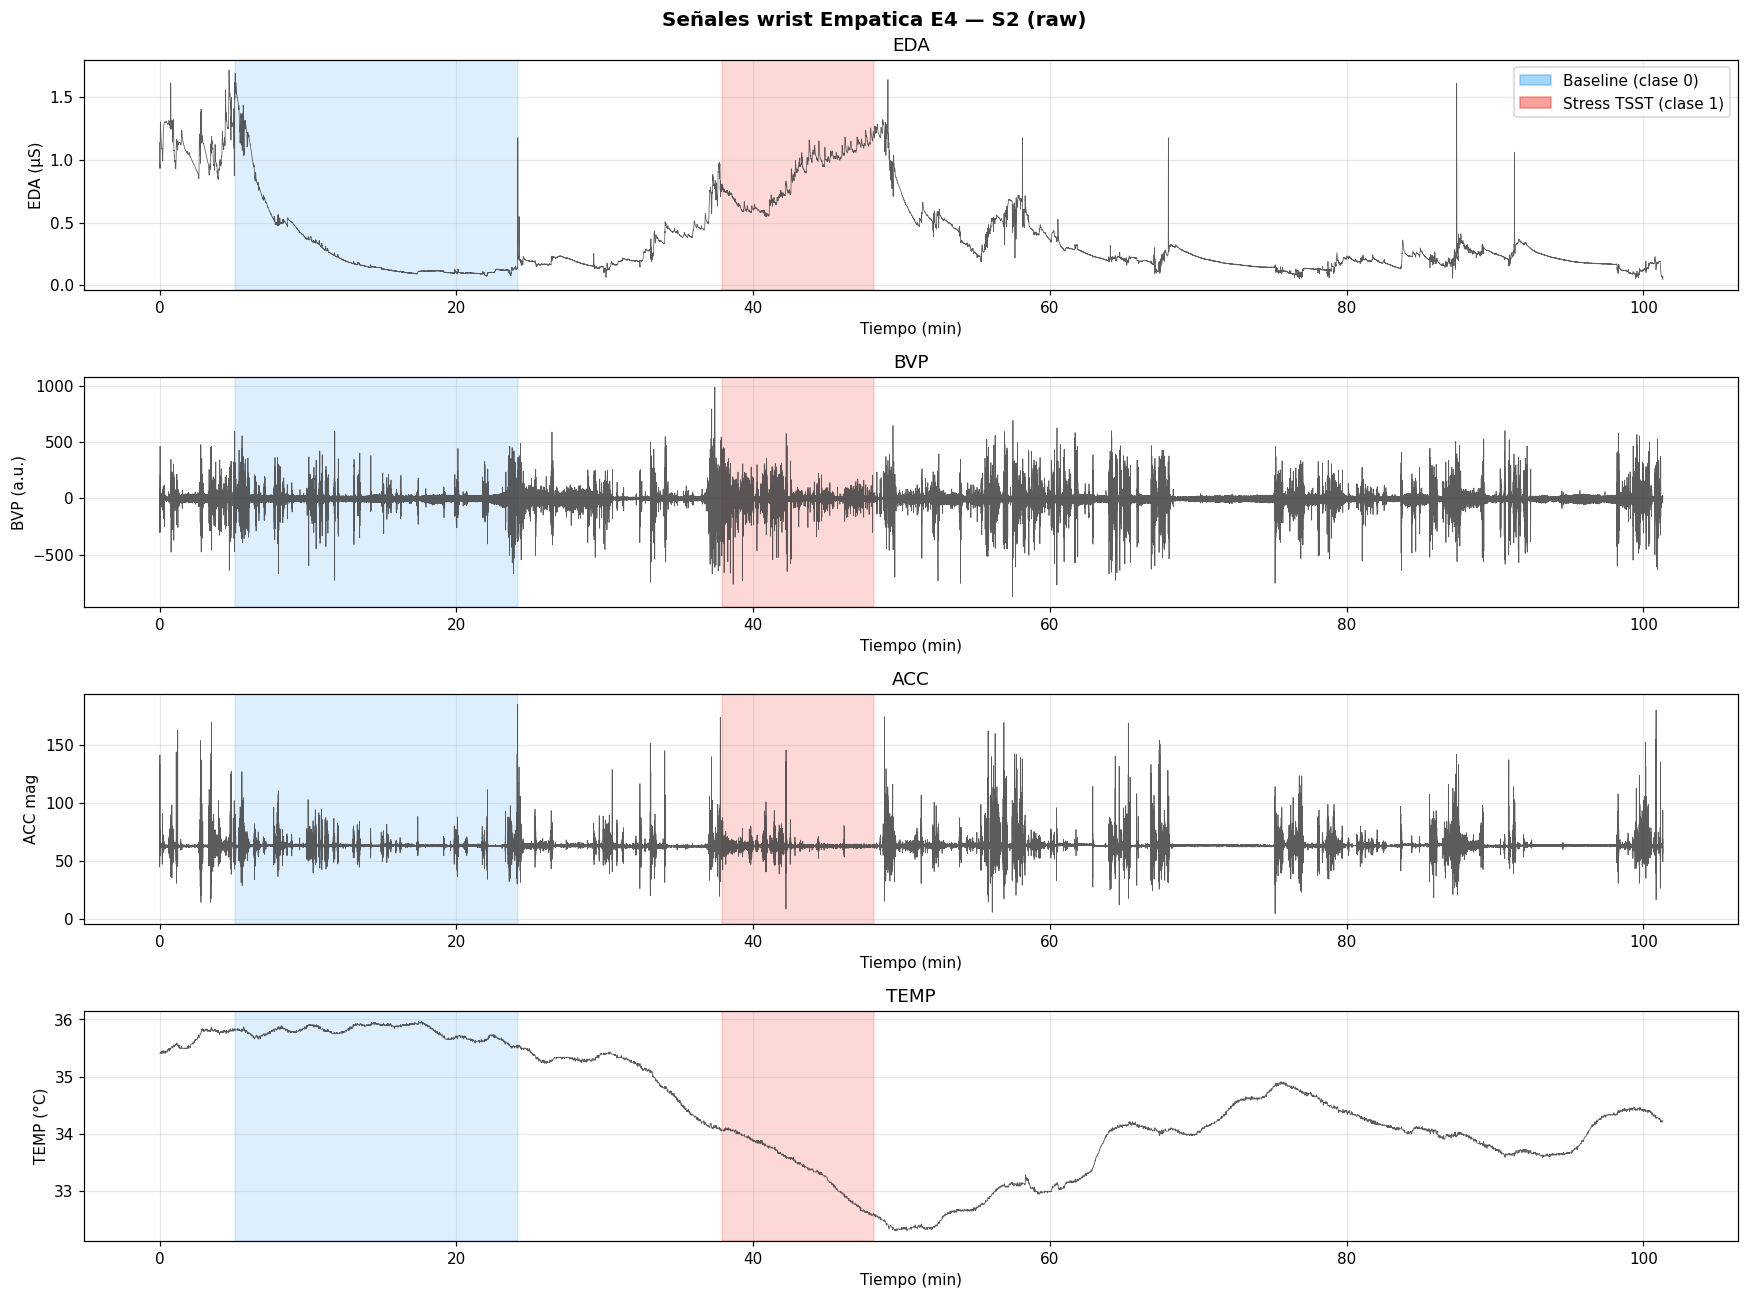

In [4]:
# ── VISUALIZACIÓN DE SEÑALES RAW (S2 como ejemplo) ──────────────────────────
subj_ex = 'S2'
d = ALL_DATA[subj_ex]

t_eda  = np.arange(len(d['EDA']))  / FS['EDA']  / 60   # minutos
t_bvp  = np.arange(len(d['BVP']))  / FS['BVP']  / 60
t_acc  = np.arange(len(d['ACC']))  / FS['ACC']  / 60
t_temp = np.arange(len(d['TEMP'])) / FS['TEMP'] / 60

# Regiones de label por tiempo (en minutos)
lbl_700 = d['labels_700']
t_lbl   = np.arange(len(lbl_700)) / FS_LABEL / 60

def label_spans(lbl_arr, t_arr, target_label):
    spans = []
    in_span, t0 = False, 0
    for i, (t, v) in enumerate(zip(t_arr, lbl_arr)):
        if v == target_label and not in_span:
            in_span, t0 = True, t
        elif v != target_label and in_span:
            spans.append((t0, t)); in_span = False
    if in_span: spans.append((t0, t_arr[-1]))
    return spans

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=False)
fig.suptitle(f'Señales wrist Empatica E4 — {subj_ex} (raw)', fontsize=13, fontweight='bold')

signal_pairs = [
    (axes[0], t_eda,  d['EDA'],          d['label_EDA'],  'EDA (μS)',    'EDA'),
    (axes[1], t_bvp,  d['BVP'],          d['label_BVP'],  'BVP (a.u.)',  'BVP'),
    (axes[2], t_acc,  np.sqrt((d['ACC']**2).sum(axis=1)), d['label_ACC'], 'ACC mag', 'ACC'),
    (axes[3], t_temp, d['TEMP'],         d['label_TEMP'], 'TEMP (°C)',   'TEMP'),
]
for ax, t, sig, lbl_sig, ylabel, name in signal_pairs:
    ax.plot(t, sig, linewidth=0.5, color='#333333', alpha=0.8)
    for t0, t1 in label_spans(lbl_sig, t, LABEL_BASELINE):
        ax.axvspan(t0, t1, alpha=0.15, color=COLORS['baseline'])
    for t0, t1 in label_spans(lbl_sig, t, LABEL_STRESS):
        ax.axvspan(t0, t1, alpha=0.20, color=COLORS['stress'])
    ax.set_ylabel(ylabel); ax.set_xlabel('Tiempo (min)'); ax.set_title(name)
    ax.grid(True, alpha=0.3)

p1 = mpatches.Patch(color=COLORS['baseline'], alpha=0.4, label='Baseline (clase 0)')
p2 = mpatches.Patch(color=COLORS['stress'],   alpha=0.5, label='Stress TSST (clase 1)')
axes[0].legend(handles=[p1, p2], loc='upper right')
plt.tight_layout()
plt.savefig(OUT_DIR / 'figures' / '01_seniales_raw.png', bbox_inches='tight')
plt.show()

---
## 3. Distribución de Labels y Balance de Clases

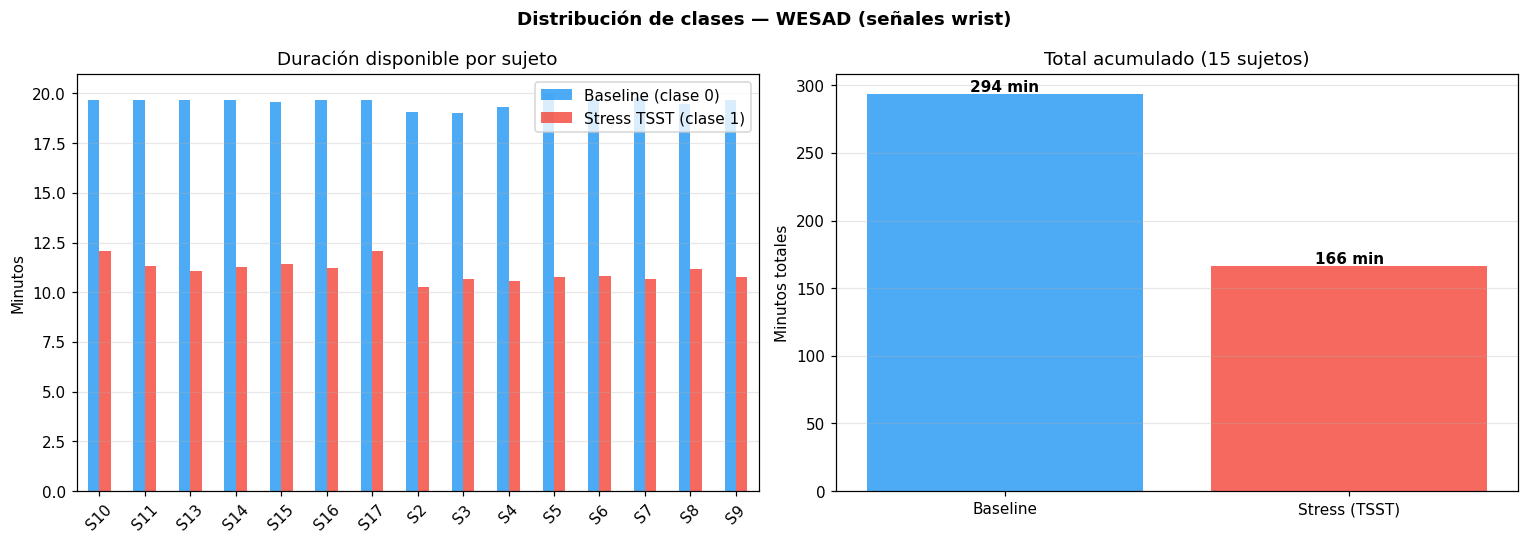

Ratio desbalance total: 1.77:1 (Baseline:Stress)
Total baseline: 294 min | Total stress: 166 min


In [5]:
# ── BALANCE DE CLASES POR SUJETO ────────────────────────────────────────────
balance_records = []
for subj, d in ALL_DATA.items():
    lbl = d['labels_700']
    for orig_label, class_label in LABELS_USE.items():
        dur_s = (lbl == orig_label).sum() / FS_LABEL
        balance_records.append({
            'subject': subj,
            'class': class_label,
            'label_name': LABEL_NAMES[class_label],
            'duration_s': dur_s,
            'duration_min': dur_s / 60
        })

balance_df = pd.DataFrame(balance_records)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribución de clases — WESAD (señales wrist)', fontsize=12, fontweight='bold')

# Duración por sujeto y clase
pivot = balance_df.pivot(index='subject', columns='label_name', values='duration_min')
pivot.plot(kind='bar', ax=axes[0], color=[COLORS['baseline'], COLORS['stress']], alpha=0.8)
axes[0].set_title('Duración disponible por sujeto')
axes[0].set_ylabel('Minutos'); axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].legend(['Baseline (clase 0)', 'Stress TSST (clase 1)'])

# Total global
totals = balance_df.groupby('label_name')['duration_min'].sum()
bars = axes[1].bar(totals.index, totals.values,
                   color=[COLORS['baseline'], COLORS['stress']], alpha=0.8)
for bar, v in zip(bars, totals.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                 f'{v:.0f} min', ha='center', fontweight='bold')
axes[1].set_title('Total acumulado (15 sujetos)')
axes[1].set_ylabel('Minutos totales'); axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(OUT_DIR / 'figures' / '02_balance_clases.png', bbox_inches='tight')
plt.show()

ratio = totals.get('Baseline', 0) / totals.get('Stress (TSST)', 1)
print(f'Ratio desbalance total: {ratio:.2f}:1 (Baseline:Stress)')
print(f'Total baseline: {totals.get("Baseline",0):.0f} min | Total stress: {totals.get("Stress (TSST)",0):.0f} min')

---
## 4. Preprocesamiento de Señales

Mismo pipeline que `modelo_A_hongn` (señal EDA idéntica — Empatica E4 a 4 Hz).

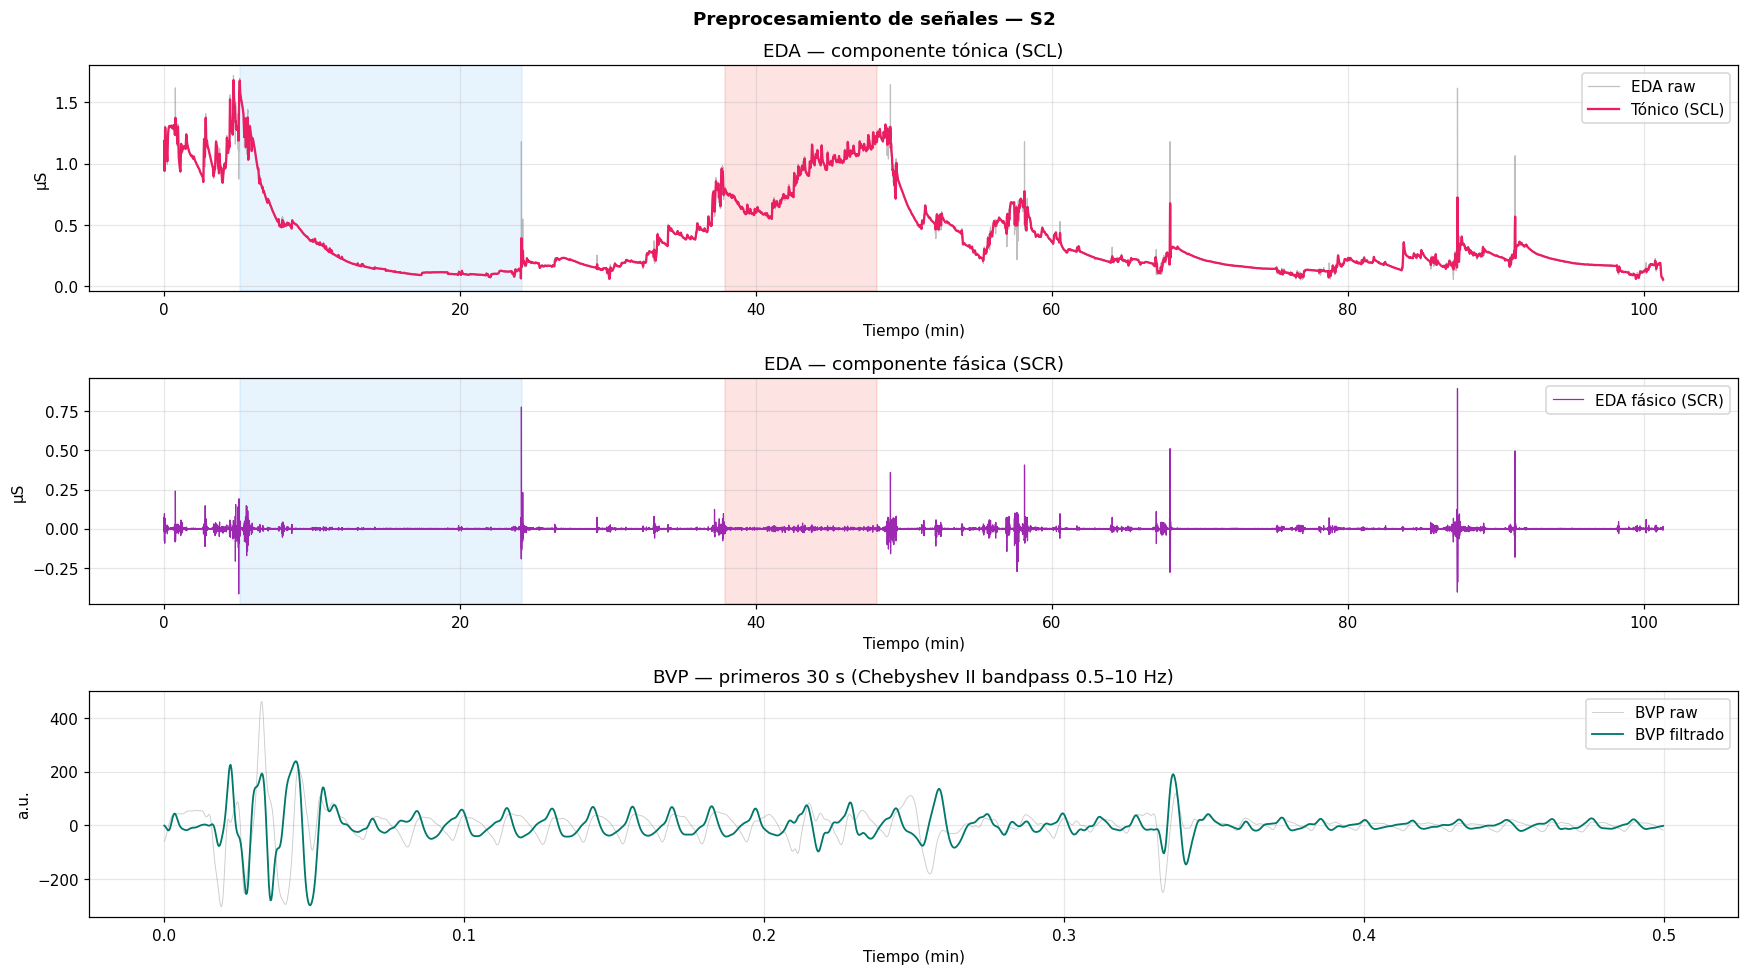

In [6]:
# ── PREPROCESAMIENTO EDA ─────────────────────────────────────────────────────
def preprocess_eda(eda_raw: np.ndarray, fs: float = 4.0):
    nyq = fs / 2
    sos = butter(N=5, Wn=1.99 / nyq, btype='low', output='sos')
    eda_filtered = sosfilt(sos, eda_raw)
    wl = int(fs * 4)
    if wl % 2 == 0: wl += 1
    eda_tonic  = savgol_filter(eda_filtered, window_length=wl, polyorder=3)
    eda_phasic = eda_filtered - eda_tonic
    return eda_filtered, eda_tonic, eda_phasic


# ── PREPROCESAMIENTO BVP ─────────────────────────────────────────────────────
def preprocess_bvp(bvp_raw: np.ndarray, fs: float = 64.0):
    nyq = fs / 2
    sos = cheby2(N=4, rs=40, Wn=[0.5 / nyq, 10.0 / nyq], btype='bandpass', output='sos')
    return sosfilt(sos, bvp_raw)


# ── VISUALIZACIÓN PREPROCESAMIENTO (S2) ──────────────────────────────────────
d  = ALL_DATA['S2']
fs = FS['EDA']
eda_f, eda_t, eda_p = preprocess_eda(d['EDA'], fs)
bvp_f = preprocess_bvp(d['BVP'], FS['BVP'])

t_eda = np.arange(len(d['EDA'])) / fs / 60
t_bvp = np.arange(len(d['BVP'])) / FS['BVP'] / 60

fig, axes = plt.subplots(3, 1, figsize=(16, 9))
fig.suptitle('Preprocesamiento de señales — S2', fontsize=12, fontweight='bold')

axes[0].plot(t_eda, d['EDA'], alpha=0.5, label='EDA raw', color='grey', lw=0.8)
axes[0].plot(t_eda, eda_t, label='Tónico (SCL)', color='#E91E63', lw=1.5)
axes[0].set_title('EDA — componente tónica (SCL)'); axes[0].set_ylabel('μS')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(t_eda, eda_p, color='#9C27B0', lw=0.8, label='EDA fásico (SCR)')
axes[1].set_title('EDA — componente fásica (SCR)'); axes[1].set_ylabel('μS')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Shadear regiones de label
lbl_e = d['label_EDA']
for ax in axes[:2]:
    for t0, t1 in label_spans(lbl_e, t_eda, LABEL_BASELINE):
        ax.axvspan(t0, t1, alpha=0.10, color=COLORS['baseline'])
    for t0, t1 in label_spans(lbl_e, t_eda, LABEL_STRESS):
        ax.axvspan(t0, t1, alpha=0.15, color=COLORS['stress'])

# BVP raw vs filtrado (segmento corto)
seg = slice(0, int(30 * FS['BVP']))
t_bvp_seg = t_bvp[seg]
axes[2].plot(t_bvp_seg, d['BVP'][seg], alpha=0.4, color='grey', lw=0.6, label='BVP raw')
axes[2].plot(t_bvp_seg, bvp_f[seg],   color='#00796B', lw=1.2, label='BVP filtrado')
axes[2].set_title('BVP — primeros 30 s (Chebyshev II bandpass 0.5–10 Hz)')
axes[2].set_ylabel('a.u.'); axes[2].legend(); axes[2].grid(True, alpha=0.3)

for ax in axes: ax.set_xlabel('Tiempo (min)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'figures' / '03_preprocesamiento.png', bbox_inches='tight')
plt.show()

---
## 5. Extracción de Características

| Señal | Features | Descripción |
|-------|----------|--------------|
| EDA | scl_mean, scl_std, scr_count, scr_density, scr_amp_mean, phasic_mean, phasic_energy | Nivel tónico + respuestas fásicas |
| ACC | acc_mag_mean, acc_mag_std, acc_mag_energy, acc_movement | Magnitud euclidiana √(X²+Y²+Z²) |
| HRV | hrv_mean_rr, hrv_sdnn, hrv_rmssd, hrv_pnn50 | Extraído del BVP 64Hz (sin ejercicio → calidad alta) |
| TEMP | temp_mean | Sin ejercicio → sin confusión termorreguladora |

In [7]:
# ── FEATURES EDA ─────────────────────────────────────────────────────────────
EDA_KEYS  = ['scl_mean','scl_std','scr_count','scr_density','scr_amp_mean','phasic_mean','phasic_energy']
ACC_KEYS  = ['acc_mag_mean','acc_mag_std','acc_mag_energy','acc_movement']
HRV_KEYS  = ['hrv_mean_rr','hrv_sdnn','hrv_rmssd','hrv_pnn50']
TEMP_KEYS = ['temp_mean']


def extract_eda_features(eda_raw: np.ndarray, fs: float = 4.0) -> dict:
    empty = {k: np.nan for k in EDA_KEYS}
    if len(eda_raw) < 8:
        return empty
    try:
        _, eda_tonic, eda_phasic = preprocess_eda(eda_raw, fs)
        feats = {
            'scl_mean'    : float(np.mean(eda_tonic)),
            'scl_std'     : float(np.std(eda_tonic)),
            'phasic_mean' : float(np.mean(eda_phasic)),
            'phasic_energy': float(np.sum(eda_phasic**2) / len(eda_phasic)),
        }
        eda_signals, info = nk.eda_process(eda_raw, sampling_rate=int(fs))
        scr_peaks   = info.get('SCR_Peaks', [])
        scr_heights = info.get('SCR_Height', [])
        n_scr = len(scr_peaks) if scr_peaks is not None else 0
        dur_s = len(eda_raw) / fs
        feats['scr_count']    = n_scr
        feats['scr_density']  = n_scr / (dur_s / 60.0) if dur_s > 0 else 0.0
        feats['scr_amp_mean'] = float(np.nanmean(scr_heights)) if n_scr > 0 else 0.0
        return feats
    except Exception:
        return empty


# ── FEATURES ACC ─────────────────────────────────────────────────────────────
def extract_acc_features(acc_raw: np.ndarray) -> dict:
    empty = {k: np.nan for k in ACC_KEYS}
    if acc_raw.shape[0] < 2:
        return empty
    try:
        mag = np.sqrt((acc_raw**2).sum(axis=1))
        return {
            'acc_mag_mean'  : float(np.mean(mag)),
            'acc_mag_std'   : float(np.std(mag)),
            'acc_mag_energy': float(np.mean(mag**2)),
            'acc_movement'  : float(np.sum(np.abs(np.diff(mag))) / len(mag)),
        }
    except Exception:
        return empty


# ── FEATURES HRV (desde BVP 64Hz) ───────────────────────────────────────────
def extract_hrv_from_bvp(bvp_raw: np.ndarray, fs: float = 64.0) -> dict:
    empty = {k: np.nan for k in HRV_KEYS}
    if len(bvp_raw) < fs * 10:  # mínimo 10 segundos
        return empty
    try:
        bvp_f = preprocess_bvp(bvp_raw, fs)
        signals, info = nk.ppg_process(bvp_f, sampling_rate=int(fs))
        peaks = info.get('PPG_Peaks', [])
        if peaks is None or len(peaks) < 5:
            return empty
        rr_ms = np.diff(peaks) / fs * 1000  # ms
        # Filtro fisiológico: RR entre 300-2000 ms (30-200 bpm)
        rr_ms = rr_ms[(rr_ms >= 300) & (rr_ms <= 2000)]
        if len(rr_ms) < 4:
            return empty
        diff_rr = np.diff(rr_ms)
        return {
            'hrv_mean_rr': float(np.mean(rr_ms)),
            'hrv_sdnn'   : float(np.std(rr_ms, ddof=1)),
            'hrv_rmssd'  : float(np.sqrt(np.mean(diff_rr**2))),
            'hrv_pnn50'  : float(np.sum(np.abs(diff_rr) > 50) / len(diff_rr) * 100),
        }
    except Exception:
        return empty


# ── FEATURES TEMP ─────────────────────────────────────────────────────────────
def extract_temp_features(temp_raw: np.ndarray) -> dict:
    if len(temp_raw) == 0:
        return {'temp_mean': np.nan}
    return {'temp_mean': float(np.nanmean(temp_raw))}


print('Funciones de extracción definidas:', EDA_KEYS + ACC_KEYS + HRV_KEYS + TEMP_KEYS)

Funciones de extracción definidas: ['scl_mean', 'scl_std', 'scr_count', 'scr_density', 'scr_amp_mean', 'phasic_mean', 'phasic_energy', 'acc_mag_mean', 'acc_mag_std', 'acc_mag_energy', 'acc_movement', 'hrv_mean_rr', 'hrv_sdnn', 'hrv_rmssd', 'hrv_pnn50', 'temp_mean']


---
## 6. Pipeline de Ventaneo y Construcción del Dataset

In [8]:
# ── VENTANEO 60s / 30s step ──────────────────────────────────────────────────
WINDOW_S    = 60     # segundos
STEP_S      = 30     # paso (50% overlap)
MIN_LABEL_PURITY = 0.90  # ≥90% mismo label en la ventana


def window_label(labels_signal: np.ndarray, start: int, end: int) -> int:
    """
    Determina el label de una ventana por mayoría (≥90% mismo label).
    Retorna -1 si la ventana es mixta o contiene label 0.
    """
    seg = labels_signal[start:end]
    if len(seg) == 0:
        return -1
    # Excluir ventanas con label 0 (undefined)
    if (seg == 0).any():
        non_zero = seg[seg != 0]
        if len(non_zero) / len(seg) < MIN_LABEL_PURITY:
            return -1
        seg = non_zero
    vals, counts = np.unique(seg, return_counts=True)
    dominant_label = vals[np.argmax(counts)]
    purity = counts.max() / len(seg)
    if purity < MIN_LABEL_PURITY:
        return -1
    return int(dominant_label)


windowed_records = []

for subj, d in ALL_DATA.items():
    eda_raw  = d['EDA']
    bvp_raw  = d['BVP']
    acc_raw  = d['ACC']
    temp_raw = d['TEMP']
    lbl_eda  = d['label_EDA']
    lbl_bvp  = d['label_BVP']
    lbl_acc  = d['label_ACC']
    lbl_temp = d['label_TEMP']

    win_n_eda  = int(WINDOW_S * FS['EDA'])
    step_n_eda = int(STEP_S   * FS['EDA'])
    win_n_bvp  = int(WINDOW_S * FS['BVP'])
    step_n_bvp = int(STEP_S   * FS['BVP'])
    win_n_acc  = int(WINDOW_S * FS['ACC'])
    step_n_acc = int(STEP_S   * FS['ACC'])

    win_idx = 0
    for i_eda in range(0, len(eda_raw) - win_n_eda + 1, step_n_eda):
        # Determinar label de la ventana (por EDA label)
        raw_label = window_label(lbl_eda, i_eda, i_eda + win_n_eda)
        if raw_label not in LABELS_USE:
            win_idx += 1
            continue

        class_label = LABELS_USE[raw_label]

        # Extraer segmentos sincronizados para cada señal
        i_bvp = int(i_eda * FS['BVP'] / FS['EDA'])
        i_acc = int(i_eda * FS['ACC'] / FS['EDA'])

        win_eda  = eda_raw [i_eda : i_eda + win_n_eda]
        win_bvp  = bvp_raw [i_bvp : i_bvp + win_n_bvp]
        win_acc  = acc_raw [i_acc : i_acc + win_n_acc]
        win_temp = temp_raw[i_eda : i_eda + win_n_eda]

        eda_feats  = extract_eda_features(win_eda,  FS['EDA'])
        acc_feats  = extract_acc_features(win_acc)
        hrv_feats  = extract_hrv_from_bvp(win_bvp,  FS['BVP'])
        temp_feats = extract_temp_features(win_temp)

        record = {
            'subject'  : subj,
            'label'    : class_label,
            'raw_label': raw_label,
            'window_id': win_idx,
            't_start_s': round(i_eda / FS['EDA'], 1),
        }
        record.update(eda_feats)
        record.update(acc_feats)
        record.update(hrv_feats)
        record.update(temp_feats)
        windowed_records.append(record)
        win_idx += 1


windows_df = pd.DataFrame(windowed_records)
windows_df.to_csv(OUT_DIR / 'dataset_windowed.csv', index=False)

print(f'Dataset construido: {len(windows_df)} ventanas')
print(f'  Clase 0 (Baseline): {(windows_df.label==0).sum()}')
print(f'  Clase 1 (Stress)  : {(windows_df.label==1).sum()}')
ratio = (windows_df.label==0).sum() / max((windows_df.label==1).sum(), 1)
print(f'  Ratio: {ratio:.2f}:1')
print(f'\nNaN por feature:')
ALL_FEAT_KEYS = EDA_KEYS + ACC_KEYS + HRV_KEYS + TEMP_KEYS
nan_counts = windows_df[ALL_FEAT_KEYS].isna().sum()
for feat, n in nan_counts.items():
    pct = n/len(windows_df)*100
    status = '✓' if n == 0 else ('⚠' if pct < 20 else '✗')
    print(f'  {status} {feat:25s}: {n} NaN ({pct:.1f}%)')

Dataset construido: 869 ventanas
  Clase 0 (Baseline): 562
  Clase 1 (Stress)  : 307
  Ratio: 1.83:1

NaN por feature:
  ✓ scl_mean                 : 0 NaN (0.0%)
  ✓ scl_std                  : 0 NaN (0.0%)
  ✓ scr_count                : 0 NaN (0.0%)
  ✓ scr_density              : 0 NaN (0.0%)
  ✓ scr_amp_mean             : 0 NaN (0.0%)
  ✓ phasic_mean              : 0 NaN (0.0%)
  ✓ phasic_energy            : 0 NaN (0.0%)
  ✓ acc_mag_mean             : 0 NaN (0.0%)
  ✓ acc_mag_std              : 0 NaN (0.0%)
  ✓ acc_mag_energy           : 0 NaN (0.0%)
  ✓ acc_movement             : 0 NaN (0.0%)
  ✓ hrv_mean_rr              : 0 NaN (0.0%)
  ✓ hrv_sdnn                 : 0 NaN (0.0%)
  ✓ hrv_rmssd                : 0 NaN (0.0%)
  ✓ hrv_pnn50                : 0 NaN (0.0%)
  ✓ temp_mean                : 0 NaN (0.0%)


---
## 7. Análisis Exploratorio por Clase

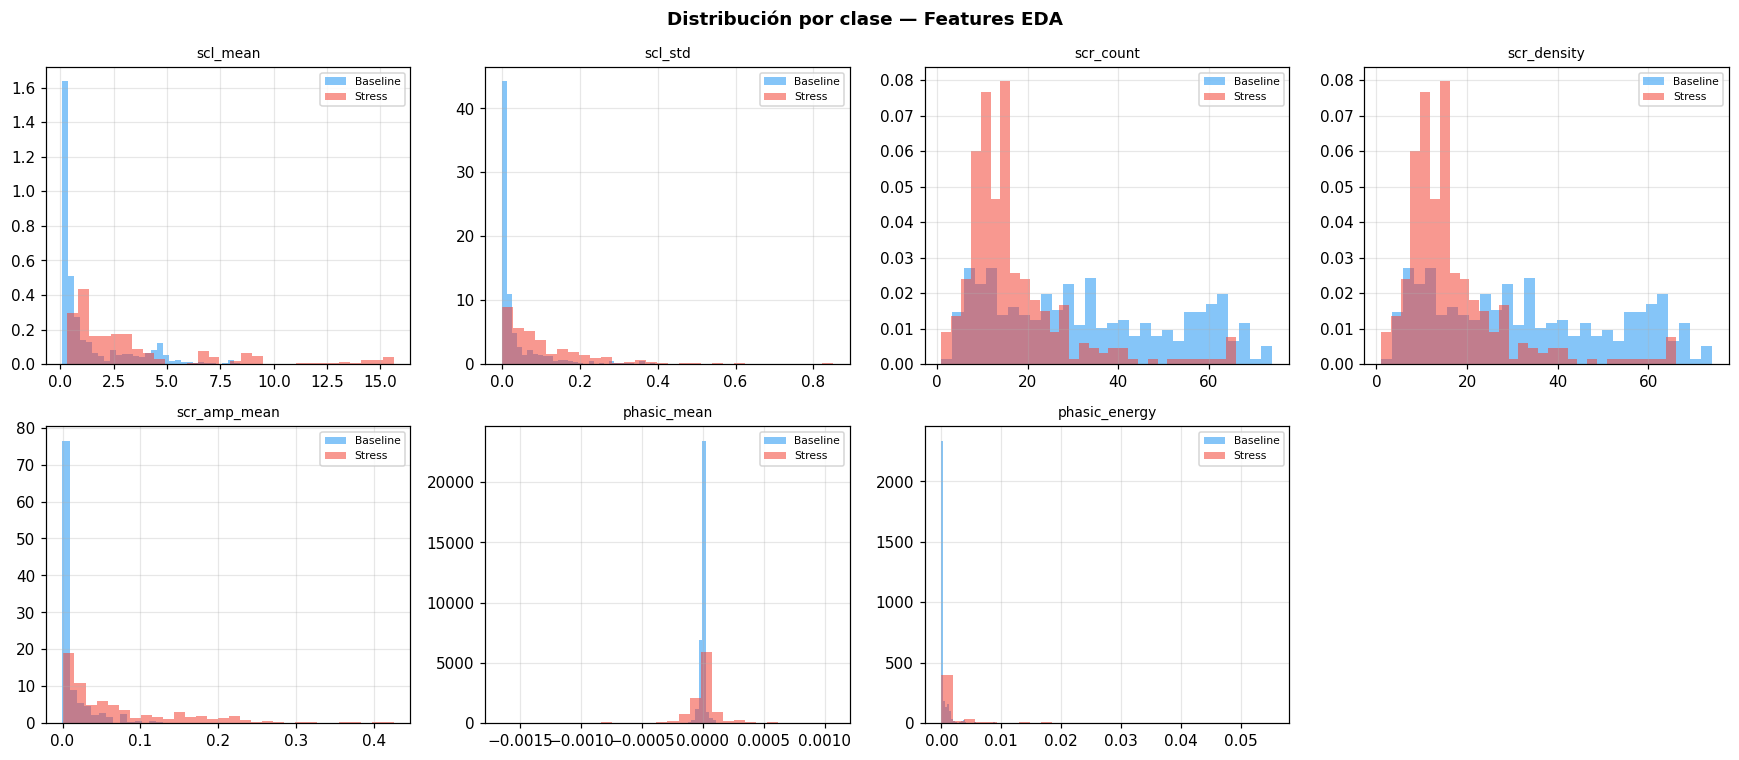

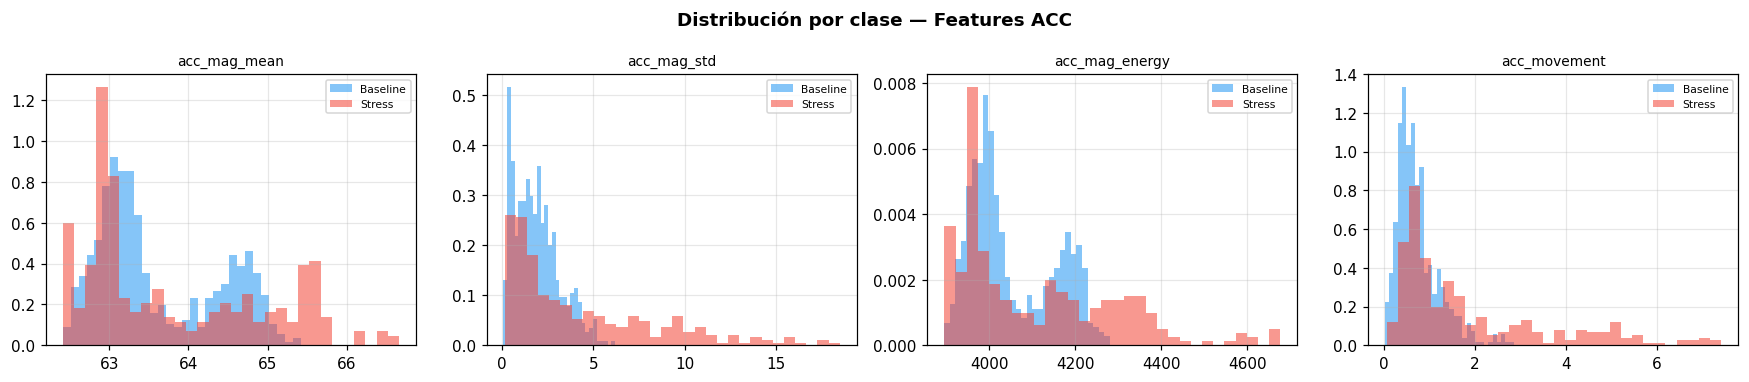

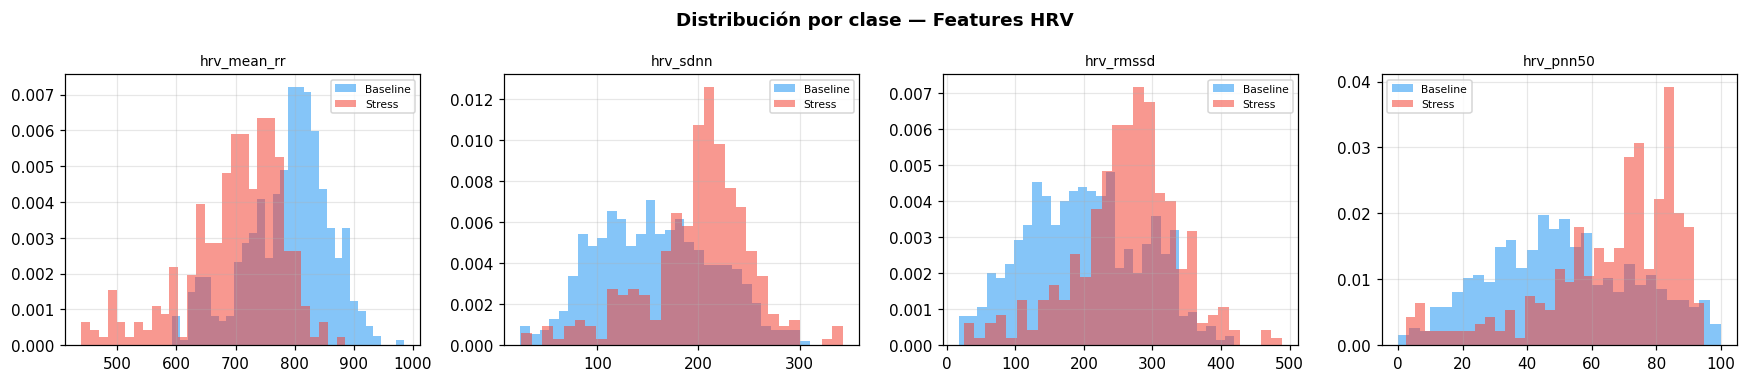

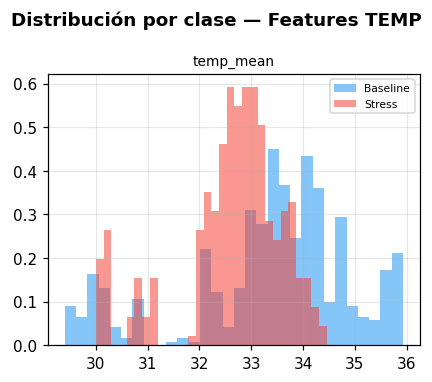

In [9]:
# ── DISTRIBUCIONES POR CLASE ─────────────────────────────────────────────────
feat_groups = {
    'EDA': EDA_KEYS,
    'ACC': ACC_KEYS,
    'HRV': HRV_KEYS,
    'TEMP': TEMP_KEYS,
}

for group_name, feats in feat_groups.items():
    avail = [f for f in feats if windows_df[f].notna().sum() > 10]
    if not avail:
        print(f'{group_name}: sin datos disponibles')
        continue

    ncols = min(4, len(avail))
    nrows = (len(avail) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*4, nrows*3.5))
    axes = np.array(axes).flatten()
    fig.suptitle(f'Distribución por clase — Features {group_name}', fontsize=12, fontweight='bold')

    for idx, feat in enumerate(avail):
        ax = axes[idx]
        for cls, color, name in [(0, COLORS['c0'], 'Baseline'), (1, COLORS['c1'], 'Stress')]:
            vals = windows_df[windows_df.label == cls][feat].dropna()
            ax.hist(vals, bins=30, alpha=0.55, color=color, label=name, density=True)
        ax.set_title(feat, fontsize=9); ax.set_xlabel(''); ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

    for idx in range(len(avail), len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.savefig(OUT_DIR / 'figures' / f'04_dist_{group_name.lower()}.png', bbox_inches='tight')
    plt.show()

---
## 8. Análisis Estadístico de Separabilidad

In [10]:
# ── MANN-WHITNEY U + COHEN'S D ───────────────────────────────────────────────
def cohens_d(x, y):
    nx, ny = len(x), len(y)
    if nx < 2 or ny < 2: return np.nan
    pooled_std = np.sqrt(((nx-1)*np.std(x,ddof=1)**2 + (ny-1)*np.std(y,ddof=1)**2) / (nx+ny-2))
    if pooled_std < 1e-10: return np.nan
    return (np.mean(x) - np.mean(y)) / pooled_std

def effect_label(d):
    d = abs(d)
    if np.isnan(d): return 'N/A'
    if d < 0.2:  return 'despreciable'
    if d < 0.5:  return 'pequeño'
    if d < 0.8:  return 'mediano'
    return 'grande'


baseline_df = windows_df[windows_df.label == 0]
stress_df   = windows_df[windows_df.label == 1]

test_records = []
for feat in ALL_FEAT_KEYS:
    x = baseline_df[feat].dropna().values
    y = stress_df[feat].dropna().values
    if len(x) < 5 or len(y) < 5:
        continue
    stat, p = mannwhitneyu(x, y, alternative='two-sided')
    d = cohens_d(x, y)
    test_records.append({
        'feature'    : feat,
        'n_baseline' : len(x),
        'n_stress'   : len(y),
        'mean_baseline': x.mean(),
        'mean_stress'  : y.mean(),
        'p_value'    : p,
        'significant': p < 0.05,
        'cohens_d'   : d,
        'effect'     : effect_label(d),
    })

test_df = pd.DataFrame(test_records).sort_values('cohens_d', key=abs, ascending=False)
test_df.to_csv(OUT_DIR / 'statistical_tests.csv', index=False)

print('=== SEPARABILIDAD: Baseline vs Stress (TSST) ===')
print(f'\n{"Feature":25s} {"p-valor":>10} {"d Cohen":>9} {"Efecto":>14} {"Sig":>5}')
print('-' * 65)
for _, row in test_df.iterrows():
    sig = '✓' if row['significant'] else '✗'
    print(f'{row["feature"]:25s} {row["p_value"]:>10.4f} {row["cohens_d"]:>9.3f} {row["effect"]:>14} {sig:>5}')

=== SEPARABILIDAD: Baseline vs Stress (TSST) ===

Feature                      p-valor   d Cohen         Efecto   Sig
-----------------------------------------------------------------
hrv_mean_rr                   0.0000     1.175         grande     ✓
scr_amp_mean                  0.0000    -1.118         grande     ✓
acc_movement                  0.0000    -1.045         grande     ✓
scr_density                   0.0000     0.942         grande     ✓
scr_count                     0.0000     0.942         grande     ✓
acc_mag_std                   0.0000    -0.933         grande     ✓
scl_std                       0.0000    -0.900         grande     ✓
scl_mean                      0.0000    -0.818         grande     ✓
hrv_sdnn                      0.0000    -0.747        mediano     ✓
hrv_rmssd                     0.0000    -0.735        mediano     ✓
hrv_pnn50                     0.0000    -0.661        mediano     ✓
phasic_energy                 0.0000    -0.633        mediano     ✓


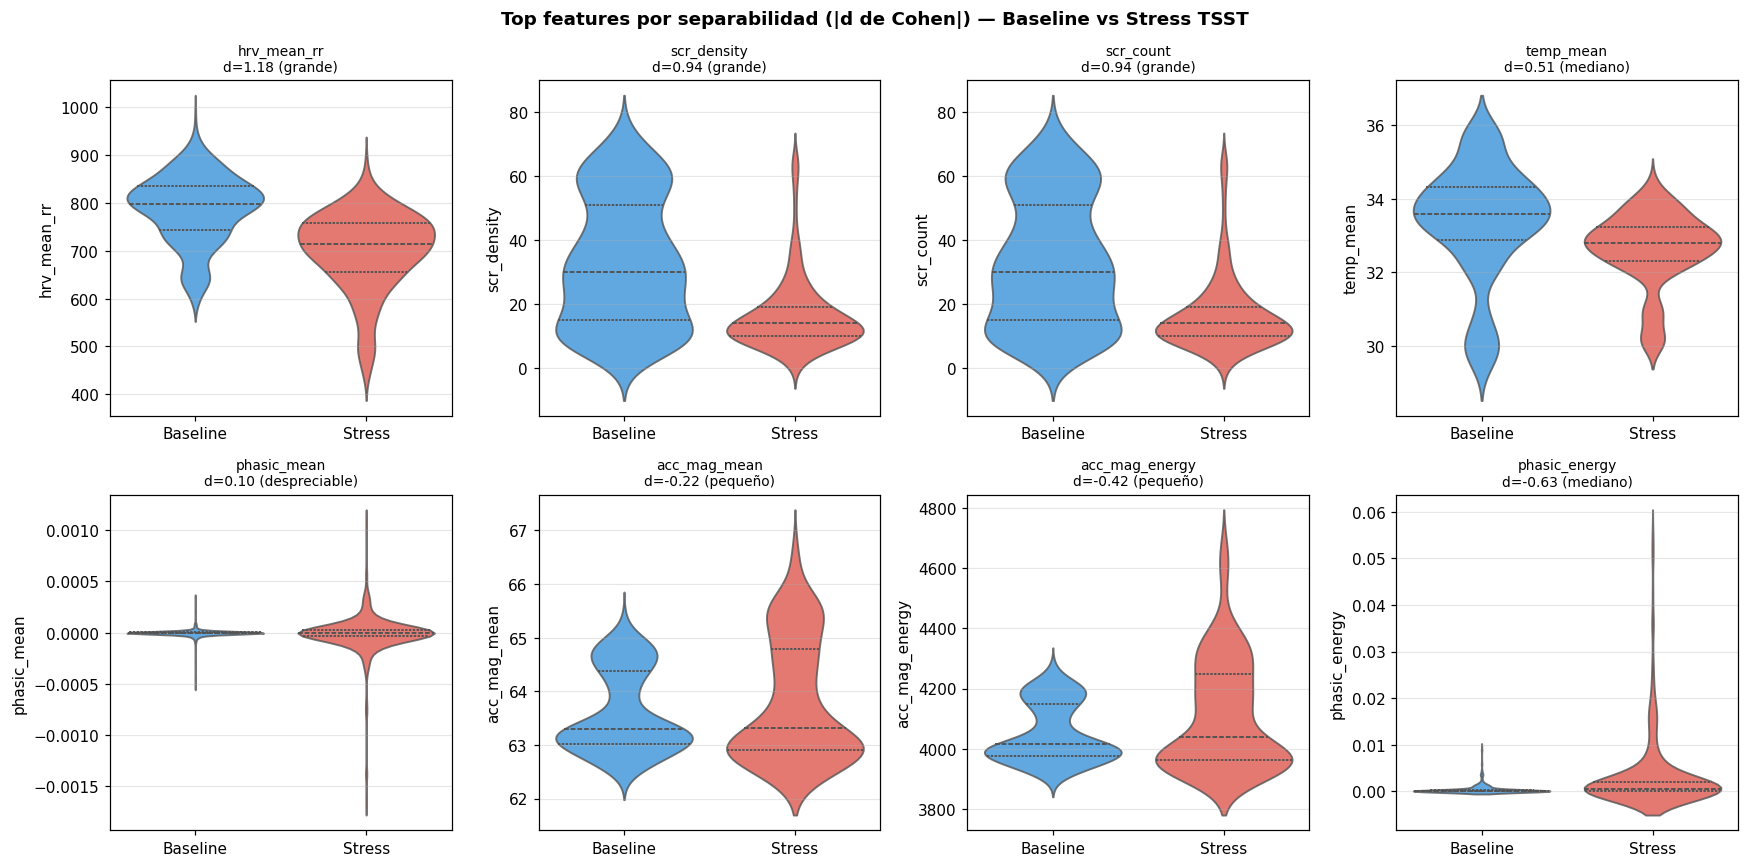

In [11]:
# ── VIOLIN PLOTS TOP FEATURES ─────────────────────────────────────────────────
top_feats = test_df.nlargest(8, 'cohens_d', keep='all')['feature'].tolist()[:8]
# Asegurar que solo hay features con datos
top_feats = [f for f in top_feats if windows_df[f].notna().sum() > 10]

if top_feats:
    ncols = 4
    nrows = (len(top_feats) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*4, nrows*4))
    axes = np.array(axes).flatten()
    fig.suptitle('Top features por separabilidad (|d de Cohen|) — Baseline vs Stress TSST',
                 fontsize=12, fontweight='bold')

    plot_df = windows_df[['label'] + top_feats].copy()
    plot_df['Clase'] = plot_df['label'].map({0: 'Baseline', 1: 'Stress'})

    for idx, feat in enumerate(top_feats):
        ax = axes[idx]
        sub = plot_df[['Clase', feat]].dropna()
        row_stat = test_df[test_df.feature == feat].iloc[0]
        sns.violinplot(data=sub, x='Clase', y=feat, ax=ax,
                       palette={'Baseline': COLORS['c0'], 'Stress': COLORS['c1']},
                       inner='quartile', alpha=0.8)
        ax.set_title(f'{feat}\nd={row_stat["cohens_d"]:.2f} ({row_stat["effect"]})', fontsize=9)
        ax.set_xlabel(''); ax.grid(True, alpha=0.3, axis='y')

    for idx in range(len(top_feats), len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.savefig(OUT_DIR / 'figures' / '05_separabilidad.png', bbox_inches='tight')
    plt.show()

---
## 9. Selección de Features y Normalización

In [12]:
# ── SELECCIÓN: features con < 20% NaN y significativas ──────────────────────
nan_pct = windows_df[ALL_FEAT_KEYS].isna().mean() * 100
available_feats = [f for f in ALL_FEAT_KEYS if nan_pct[f] < 20]

print('Features seleccionadas (< 20% NaN):')
for f in available_feats:
    stat = test_df[test_df.feature == f]
    if len(stat):
        row = stat.iloc[0]
        print(f'  {f:25s} NaN={nan_pct[f]:.1f}%  d={row["cohens_d"]:.3f} ({row["effect"]})')
    else:
        print(f'  {f:25s} NaN={nan_pct[f]:.1f}%  (sin test)')

print(f'\nTotal features seleccionadas: {len(available_feats)}')

# ── NORMALIZACIÓN Z-SCORE INTRA-SUJETO ──────────────────────────────────────
windows_norm = windows_df.copy()
for subj in windows_norm['subject'].unique():
    mask = windows_norm['subject'] == subj
    for col in available_feats:
        vals = windows_norm.loc[mask, col]
        mu, sigma = vals.mean(), vals.std()
        if sigma > 1e-10:
            windows_norm.loc[mask, col] = (vals - mu) / sigma

windows_norm.to_csv(OUT_DIR / 'dataset_windowed_normalized.csv', index=False)
print(f'\nDataset normalizado guardado: {OUT_DIR}/dataset_windowed_normalized.csv')
print(f'Forma final: {windows_norm.shape}')
print(f'Features para modelado: {available_feats}')

Features seleccionadas (< 20% NaN):
  scl_mean                  NaN=0.0%  d=-0.818 (grande)
  scl_std                   NaN=0.0%  d=-0.900 (grande)
  scr_count                 NaN=0.0%  d=0.942 (grande)
  scr_density               NaN=0.0%  d=0.942 (grande)
  scr_amp_mean              NaN=0.0%  d=-1.118 (grande)
  phasic_mean               NaN=0.0%  d=0.098 (despreciable)
  phasic_energy             NaN=0.0%  d=-0.633 (mediano)
  acc_mag_mean              NaN=0.0%  d=-0.218 (pequeño)
  acc_mag_std               NaN=0.0%  d=-0.933 (grande)
  acc_mag_energy            NaN=0.0%  d=-0.422 (pequeño)
  acc_movement              NaN=0.0%  d=-1.045 (grande)
  hrv_mean_rr               NaN=0.0%  d=1.175 (grande)
  hrv_sdnn                  NaN=0.0%  d=-0.747 (mediano)
  hrv_rmssd                 NaN=0.0%  d=-0.735 (mediano)
  hrv_pnn50                 NaN=0.0%  d=-0.661 (mediano)
  temp_mean                 NaN=0.0%  d=0.508 (mediano)

Total features seleccionadas: 16

Dataset normalizado guard

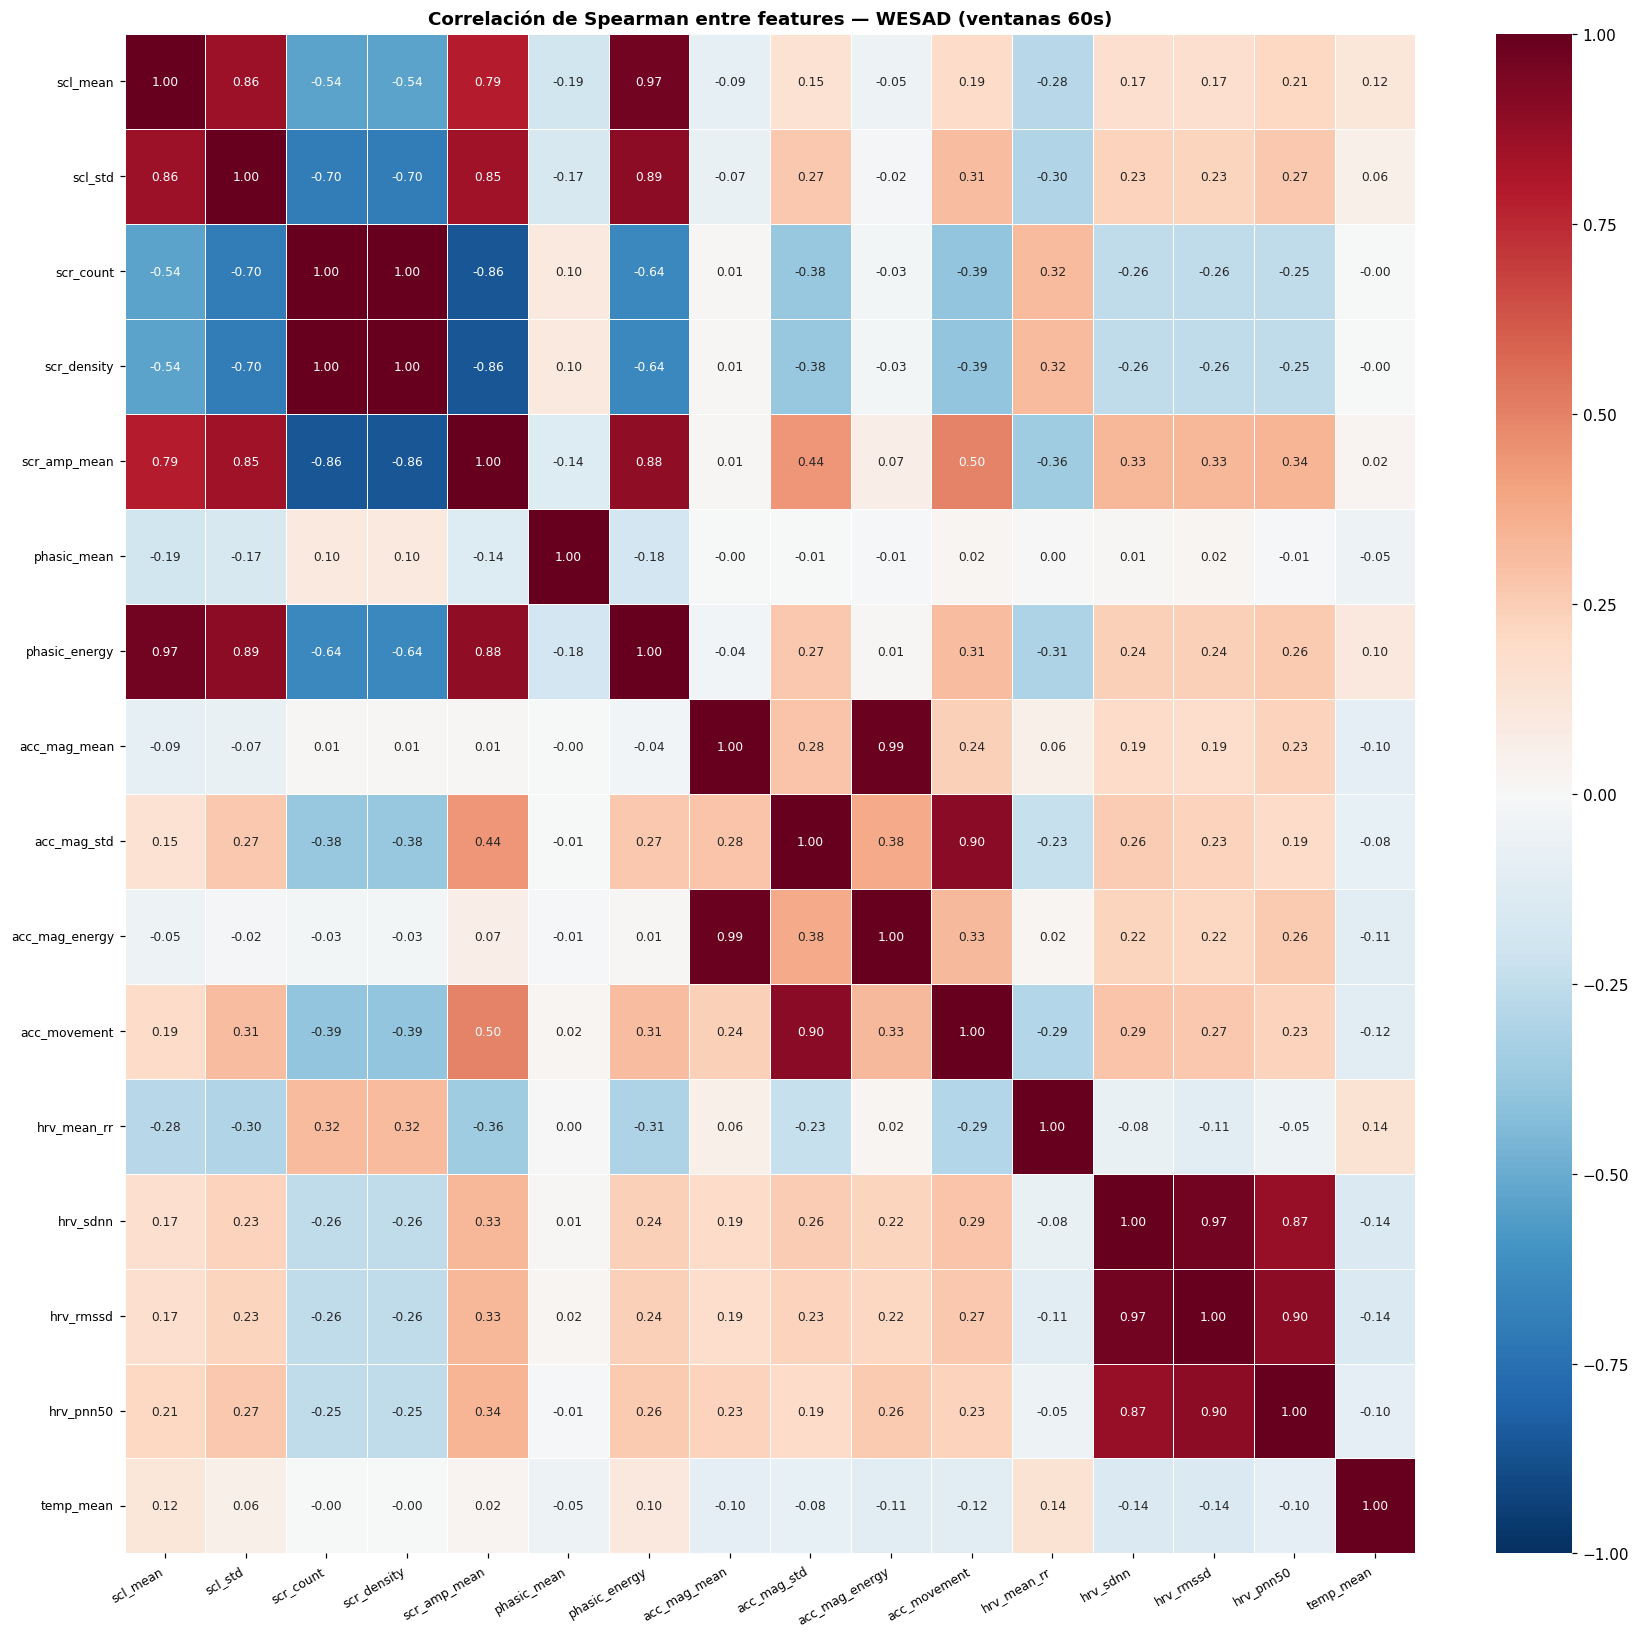

In [13]:
# ── CORRELACIÓN ENTRE FEATURES ────────────────────────────────────────────────
corr_data = windows_df[available_feats].dropna()
if len(corr_data) > 10:
    corr_matrix = corr_data.corr(method='spearman')
    fig, ax = plt.subplots(figsize=(max(8, len(available_feats)), max(7, len(available_feats)-1)))
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, vmin=-1, vmax=1, ax=ax,
                linewidths=0.5, annot_kws={'size': 8})
    ax.set_title('Correlación de Spearman entre features — WESAD (ventanas 60s)',
                 fontsize=12, fontweight='bold')
    plt.xticks(rotation=30, ha='right', fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'figures' / '06_correlacion_features.png', bbox_inches='tight')
    plt.show()

---
## 10. Resumen del EDA

In [14]:
# ── RESUMEN EJECUTIVO ────────────────────────────────────────────────────────
print('=' * 65)
print('RESUMEN EDA — WESAD (wrist E4 signals)')
print('=' * 65)
print(f'Sujetos              : {len(ALL_DATA)} (S2-S17, sin S1 y S12)')
print(f'Ventanas totales     : {len(windows_df)} (60s / 30s overlap)')
print(f'  Clase 0 (Baseline) : {(windows_df.label==0).sum()}')
print(f'  Clase 1 (Stress)   : {(windows_df.label==1).sum()}')
print(f'  Ratio              : {ratio:.2f}:1')

sig_feats = test_df[test_df['significant'] == True]
print(f'\nFeatures significativas (p<0.05): {len(sig_feats)}/{len(test_df)}')
large_ef = test_df[test_df['effect'] == 'grande']
print(f'Features con efecto grande (|d|>0.8): {len(large_ef)}')
for _, row in large_ef.iterrows():
    print(f'  {row["feature"]:25s} d={row["cohens_d"]:+.3f}')

print(f'\nFeatures disponibles para modelado: {len(available_feats)}')
print(f'  {available_feats}')

print(f'\nArchivos generados en {OUT_DIR}/')
for f in sorted(OUT_DIR.rglob('*')):
    if f.is_file():
        print(f'  {f.relative_to(OUT_DIR)} ({f.stat().st_size/1024:.1f} KB)')

RESUMEN EDA — WESAD (wrist E4 signals)
Sujetos              : 15 (S2-S17, sin S1 y S12)
Ventanas totales     : 869 (60s / 30s overlap)
  Clase 0 (Baseline) : 562
  Clase 1 (Stress)   : 307
  Ratio              : 1.83:1

Features significativas (p<0.05): 13/16
Features con efecto grande (|d|>0.8): 8
  hrv_mean_rr               d=+1.175
  scr_amp_mean              d=-1.118
  acc_movement              d=-1.045
  scr_density               d=+0.942
  scr_count                 d=+0.942
  acc_mag_std               d=-0.933
  scl_std                   d=-0.900
  scl_mean                  d=-0.818

Features disponibles para modelado: 16
  ['scl_mean', 'scl_std', 'scr_count', 'scr_density', 'scr_amp_mean', 'phasic_mean', 'phasic_energy', 'acc_mag_mean', 'acc_mag_std', 'acc_mag_energy', 'acc_movement', 'hrv_mean_rr', 'hrv_sdnn', 'hrv_rmssd', 'hrv_pnn50', 'temp_mean']

Archivos generados en ../eda_outputs/
  dataset_windowed.csv (246.1 KB)
  dataset_windowed_normalized.csv (282.1 KB)
  figures/01_